# Analyse exploratoire des données (EDA) - notebook générique

Ce notebook s'adapte à **n'importe quel fichier CSV** : il détecte automatiquement les types de colonnes
(numériques, catégorielles, dates, identifiants, texte, coordonnées GPS).

**Mode d'emploi** : modifiez uniquement la cellule *0. Configuration*, puis exécutez tout (`Run All`).

**Plan**
0. Configuration
1. Imports
2. Chargement des données
3. Aperçu général
4. Préparation et typage automatique
5. Qualité des données
6. Statistiques descriptives
7. Analyse univariée - variables numériques
8. Analyse univariée - variables catégorielles
9. Valeurs aberrantes (outliers)
10. Analyse bivariée - numérique vs numérique
11. Analyse bivariée - numérique vs catégorielle
12. Analyse bivariée - catégorielle vs catégorielle
13. Analyse de la variable cible (optionnel)
14. Analyse temporelle (si colonnes de dates)
15. Analyse géographique (si latitude / longitude)
16. Synthèse automatique
17. Export des données nettoyées

## 0. Configuration
Seule cellule à adapter à votre fichier.

In [20]:
CSV_PATH = r"C:\Users\bmd\Desktop\apartments_for_rent_classified_10K"    # <-- chemin du fichier CSV
SEP = None                        # None = détection automatique (',', ';', tabulation...)
ENCODING = None                   # None = essaie utf-8 puis latin-1
TARGET = "price"                    # nom de la variable à expliquer (optionnel), ex. "price"
UNIX_TIME_COLS = ["time"]               # colonnes contenant des timestamps Unix (secondes), ex. ["time"]
NA_VALUES = ["null", "NULL", "None", "NaN", "nan", "NA", "N/A", "n/a", "", "-", "?"]

MAX_CAT_CARD = 30                 # au-delà : colonne texte à forte cardinalité (non traitée comme catégorielle)
ID_RATIO = 0.95                   # part de valeurs uniques à partir de laquelle une colonne entière est un identifiant
MAX_PLOTS = 16                    # nombre max de colonnes tracées par section
CORR_THRESHOLD = 0.5              # seuil de corrélation forte
SAMPLE_SIZE = 5000                # taille max d'échantillon pour les nuages de points

## 1. Imports

In [21]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
%matplotlib inline

In [22]:
import os, glob

if os.path.isdir(CSV_PATH):
    csvs = glob.glob(os.path.join(CSV_PATH, "**", "*.csv"), recursive=True)
    print("Fichiers CSV trouvés dans le dossier :")
    for f in csvs:
        print("  ", f)
    if not csvs:
        raise FileNotFoundError("Aucun .csv dans ce dossier : vérifiez le contenu de l'extraction.")
    CSV_PATH = csvs[0]
    print("\nFichier utilisé :", CSV_PATH)

Fichiers CSV trouvés dans le dossier :
   C:\Users\bmd\Desktop\apartments_for_rent_classified_10K\apartments_for_rent_classified_10K.csv

Fichier utilisé : C:\Users\bmd\Desktop\apartments_for_rent_classified_10K\apartments_for_rent_classified_10K.csv


## 2. Chargement des données

In [23]:
def charger(path, sep, enc):
    encodages = [enc] if enc else ["utf-8", "latin-1"]
    derniere = None
    for e in encodages:
        try:
            df = pd.read_csv(path, sep=sep, engine="python" if sep is None else "c",
                             encoding=e, na_values=NA_VALUES)
            return df, e
        except UnicodeDecodeError as err:
            derniere = err
    raise derniere

df_raw, enc_utilise = charger(CSV_PATH, SEP, ENCODING)
print(f"Fichier chargé : {CSV_PATH} (encodage : {enc_utilise})")
print(f"Dimensions : {df_raw.shape[0]:,} lignes x {df_raw.shape[1]} colonnes")

Fichier chargé : C:\Users\bmd\Desktop\apartments_for_rent_classified_10K\apartments_for_rent_classified_10K.csv (encodage : latin-1)
Dimensions : 10,000 lignes x 22 colonnes


## 3. Aperçu général

In [24]:
display(df_raw.head(10))
display(df_raw.tail(3))

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668626895,housing/rent/apartment,"Studio apartment 2nd St NE, Uhland Terrace NE,...","This unit is located at second St NE, Uhland T...",NaN,NaN,0.00,USD,No,Thumbnail,NaN,790,$790,Monthly,101,NaN,Washington,DC,38.91,-76.99,RentLingo,1577359415
1,5664597177,housing/rent/apartment,Studio apartment 814 Schutte Road,"This unit is located at 814 Schutte Road, Evan...",NaN,NaN,1.00,USD,No,Thumbnail,NaN,425,$425,Monthly,106,814 Schutte Rd,Evansville,IN,37.97,-87.66,RentLingo,1577017063
2,5668626833,housing/rent/apartment,"Studio apartment N Scott St, 14th St N, Arling...","This unit is located at N Scott St, 14th St N,...",NaN,1.00,0.00,USD,No,Thumbnail,NaN,1390,"$1,390",Monthly,107,NaN,Arlington,VA,38.89,-77.08,RentLingo,1577359410
3,5659918074,housing/rent/apartment,Studio apartment 1717 12th Ave,"This unit is located at 1717 12th Ave, Seattle...",NaN,1.00,0.00,USD,No,Thumbnail,NaN,925,$925,Monthly,116,1717 12th Avenue,Seattle,WA,47.62,-122.33,RentLingo,1576667743
4,5668626759,housing/rent/apartment,"Studio apartment Washington Blvd, N Cleveland ...","This unit is located at Washington Blvd, N Cle...",NaN,NaN,0.00,USD,No,Thumbnail,NaN,880,$880,Monthly,125,NaN,Arlington,VA,38.87,-77.11,RentLingo,1577359401
5,5667891676,housing/rent/apartment,0 BR in New York NY 10019,**RARE GEM WITH PRIVATE OUTDOOR TERRACE****AVA...,"Dishwasher,Elevator,Patio/Deck,Pool,Storage",1.00,0.00,USD,No,Thumbnail,NaN,2475,"$2,475",Monthly,130,350 West 50th St,Manhattan,NY,40.76,-73.99,Listanza,1577289784
6,5668627426,housing/rent/apartment,Studio apartment 2432 Penmar Ave,"This unit is located at 2432 Penmar Ave, Venic...",NaN,NaN,0.00,USD,No,Thumbnail,NaN,1800,"$1,800",Monthly,132,2432 Penmar Avenue,Venice,CA,33.99,-118.46,RentLingo,1577359461
7,5668626687,housing/rent/apartment,"Studio apartment Oak St NW, 16th St NW, Washin...","This unit is located at Oak St NW, 16th St NW,...",NaN,NaN,0.00,USD,No,Thumbnail,NaN,840,$840,Monthly,136,NaN,Washington,DC,38.93,-77.03,RentLingo,1577359393
8,5668610290,housing/rent/apartment,Studio apartment 333 Hyde St,"This unit is located at 333 Hyde St, San Franc...",Refrigerator,1.00,0.00,USD,No,Thumbnail,NaN,1495,"$1,495",Monthly,138,333 Hyde St,San Francisco,CA,37.76,-122.44,RentLingo,1577358313
9,5668627023,housing/rent/apartment,"Studio apartment A St SE, 19th St SE, Washington","This unit is located at A St SE, 19th St SE, W...",NaN,NaN,0.00,USD,No,Thumbnail,NaN,890,$890,Monthly,141,NaN,Washington,DC,38.91,-77.01,RentLingo,1577359424


,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
9997,5668643292,housing/rent/apartment,Six BR 9908 Bentcross Drive,"This unit is located at 9908 Bentcross Drive, ...",NaN,8.50,6.00,USD,No,Thumbnail,NaN,11000,"$11,000",Monthly,11318,9908 Bentcross Dr,Potomac,MD,39.03,-77.24,RentLingo,1577360560
9998,5668662559,housing/rent/apartment,One BR in New York NY 10069,"Monthly Rent$4,605 -to $4,790AmenitiesThe Aldy...","Basketball,Cable or Satellite,Doorman,Hot Tub,...",NaN,1.00,USD,No,Thumbnail,NaN,4790,"$4,790",Monthly,40000,NaN,New York,NY,40.77,-73.99,Listanza,1577362186
9999,5509132540,housing/rent/apartment,Beautiful Lawrenceville Apartment for rent,"Square footage: 880 sq. feet, unit number: 150...","Gym,Patio/Deck",1.00,1.00,USD,No,No,NaN,1009,"$1,009",Monthly,880,NaN,Lawrenceville,GA,34.01,-84.00,RentDigs.com,1577362141


In [25]:
print(f"Mémoire utilisée : {df_raw.memory_usage(deep=True).sum() / 1e6:.2f} Mo\n")
df_raw.info()

Mémoire utilisée : 12.90 Mo

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             10000 non-null  int64  
 1   category       10000 non-null  object 
 2   title          10000 non-null  object 
 3   body           10000 non-null  object 
 4   amenities      6451 non-null   object 
 5   bathrooms      9966 non-null   float64
 6   bedrooms       9993 non-null   float64
 7   currency       10000 non-null  object 
 8   fee            10000 non-null  object 
 9   has_photo      10000 non-null  object 
 10  pets_allowed   5837 non-null   object 
 11  price          10000 non-null  int64  
 12  price_display  10000 non-null  object 
 13  price_type     10000 non-null  object 
 14  square_feet    10000 non-null  int64  
 15  address        6673 non-null   object 
 16  cityname       9923 non-null   object 
 17  state          9923 no

## 4. Préparation et typage automatique
- Nettoyage des noms de colonnes et des espaces
- Conversion des textes numériques (ex. `$2,195`), des dates et des timestamps Unix
- Classement des colonnes : numériques, catégorielles, dates, identifiants, texte, booléennes

In [26]:
df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]

# espaces parasites dans les textes
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

# timestamps Unix déclarés
for c in UNIX_TIME_COLS:
    if c in df.columns:
        df[c] = pd.to_datetime(pd.to_numeric(df[c], errors="coerce"), unit="s", errors="coerce")

# textes qui ressemblent à des nombres ou à des dates
for c in df.select_dtypes(include="object").columns:
    s = df[c].dropna()
    if s.empty:
        continue
    echantillon = s.sample(min(500, len(s)), random_state=0)
    # nombres (ex. "$2,195", "12 %")
    propre = echantillon.str.replace(r"[,$€£%\s]", "", regex=True)
    if pd.to_numeric(propre, errors="coerce").notna().mean() > 0.95:
        df[c] = pd.to_numeric(df[c].str.replace(r"[,$€£%\s]", "", regex=True), errors="coerce")
        continue
    # dates (on exige des séparateurs de type date pour éviter les faux positifs)
    if echantillon.str.contains(r"\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}").mean() > 0.9:
        conv = pd.to_datetime(echantillon, errors="coerce")
        if conv.notna().mean() > 0.9:
            df[c] = pd.to_datetime(df[c], errors="coerce")

# classement des colonnes
num_cols, cat_cols, date_cols, text_cols, id_cols, bool_cols = [], [], [], [], [], []
n = len(df)
for c in df.columns:
    s = df[c]
    nun = s.nunique(dropna=True)
    if pd.api.types.is_datetime64_any_dtype(s):
        date_cols.append(c)
    elif pd.api.types.is_bool_dtype(s) or (nun == 2 and not pd.api.types.is_numeric_dtype(s)):
        bool_cols.append(c) if pd.api.types.is_bool_dtype(s) else cat_cols.append(c)
    elif pd.api.types.is_numeric_dtype(s):
        if pd.api.types.is_integer_dtype(s) and n > 20 and nun >= ID_RATIO * n:
            id_cols.append(c)
        elif nun <= 2:
            cat_cols.append(c)
        else:
            num_cols.append(c)
    else:
        if n > 20 and nun >= ID_RATIO * n:
            id_cols.append(c)
        elif nun <= MAX_CAT_CARD:
            cat_cols.append(c)
        else:
            text_cols.append(c)

resume = pd.DataFrame({
    "type": ["numériques", "catégorielles", "dates", "identifiants", "texte / forte cardinalité", "booléennes"],
    "nombre": [len(num_cols), len(cat_cols), len(date_cols), len(id_cols), len(text_cols), len(bool_cols)],
    "colonnes": [num_cols, cat_cols, date_cols, id_cols, text_cols, bool_cols],
})
display(resume)
cat_cols = cat_cols + bool_cols

,type,nombre,colonnes
0,numériques,7,"[bathrooms, bedrooms, price, price_display, sq..."
1,catégorielles,7,"[category, currency, fee, has_photo, pets_allo..."
2,dates,1,[time]
3,identifiants,2,"[id, body]"
4,texte / forte cardinalité,5,"[title, amenities, address, cityname, state]"
5,booléennes,0,[]


## 5. Qualité des données
Valeurs manquantes, doublons, colonnes constantes, cardinalité, incohérences.

,n_manquants,pct_manquants
pets_allowed,4163,41.63
amenities,3549,35.49
address,3327,33.27
state,77,0.77
cityname,77,0.77
bathrooms,34,0.34
longitude,10,0.10
latitude,10,0.10
bedrooms,7,0.07
price_display,2,0.02


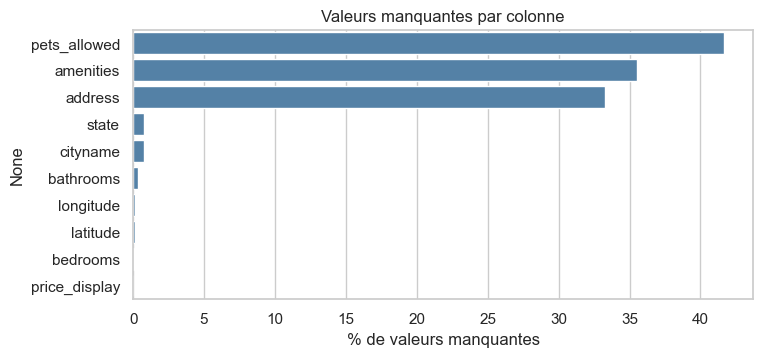

In [27]:
# 5.1 Valeurs manquantes
manq = pd.DataFrame({
    "n_manquants": df.isna().sum(),
    "pct_manquants": df.isna().mean() * 100,
}).sort_values("pct_manquants", ascending=False)
display(manq[manq["n_manquants"] > 0] if (manq["n_manquants"] > 0).any() else "Aucune valeur manquante")

if (manq["n_manquants"] > 0).any():
    m = manq[manq["n_manquants"] > 0]
    plt.figure(figsize=(8, max(3, 0.35 * len(m))))
    sns.barplot(x=m["pct_manquants"], y=m.index, color="steelblue")
    plt.xlabel("% de valeurs manquantes")
    plt.title("Valeurs manquantes par colonne")
    plt.show()

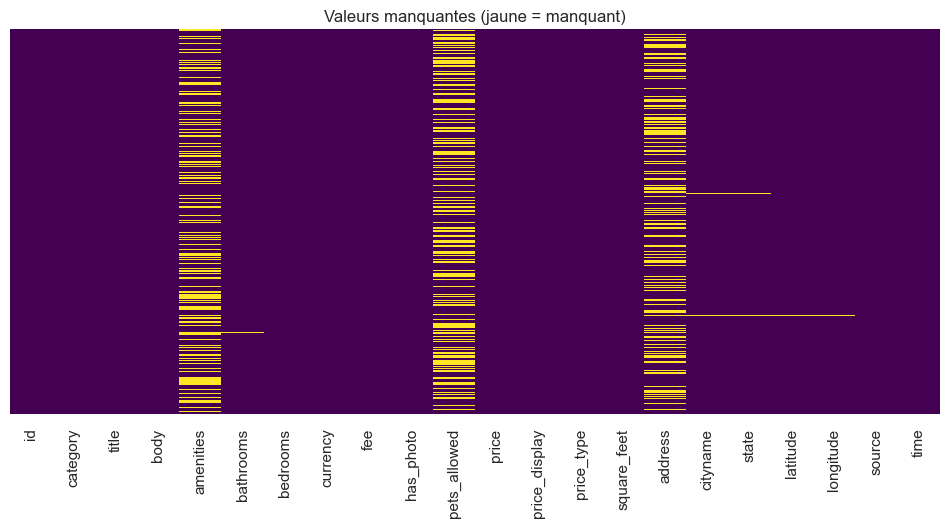

In [28]:
# 5.2 Carte des valeurs manquantes (échantillon de lignes)
if df.isna().any().any():
    ech = df.sample(min(len(df), 500), random_state=0)
    plt.figure(figsize=(12, 5))
    sns.heatmap(ech.isna(), cbar=False, yticklabels=False, cmap="viridis")
    plt.title("Valeurs manquantes (jaune = manquant)")
    plt.show()

In [29]:
# 5.3 Doublons, colonnes constantes, cardinalité
print(f"Lignes entièrement dupliquées : {df.duplicated().sum():,}")
for c in id_cols:
    print(f"Identifiants dupliqués dans '{c}' : {df[c].duplicated().sum():,}")

constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(f"Colonnes constantes (à supprimer) : {constantes}")

card = pd.DataFrame({"n_uniques": df.nunique(), "pct_uniques": df.nunique() / len(df) * 100,
                     "dtype": df.dtypes.astype(str)}).sort_values("n_uniques")
display(card)

Lignes entièrement dupliquées : 0
Identifiants dupliqués dans 'id' : 0
Identifiants dupliqués dans 'body' : 39
Colonnes constantes (à supprimer) : ['currency', 'fee']


,n_uniques,pct_uniques,dtype
fee,1,0.01,object
currency,1,0.01,object
price_type,3,0.03,object
has_photo,3,0.03,object
pets_allowed,3,0.03,object
category,3,0.03,object
bedrooms,10,0.10,float64
source,12,0.12,object
bathrooms,14,0.14,float64
state,51,0.51,object


In [30]:
# 5.4 Incohérences sur les variables numériques
lignes = []
for c in num_cols:
    s = df[c].dropna()
    lignes.append({"colonne": c, "valeurs_negatives": int((s < 0).sum()),
                   "valeurs_nulles": int((s == 0).sum()),
                   "valeurs_infinies": int(np.isinf(s).sum())})
display(pd.DataFrame(lignes) if lignes else "Aucune variable numérique")

,colonne,valeurs_negatives,valeurs_nulles,valeurs_infinies
0,bathrooms,0,0,0
1,bedrooms,0,198,0
2,price,0,0,0
3,price_display,0,0,0
4,square_feet,0,0,0
5,latitude,0,0,0
6,longitude,9990,0,0


## 6. Statistiques descriptives

In [31]:
if num_cols:
    d = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
    d["asymétrie (skew)"] = df[num_cols].skew()
    d["aplatissement (kurtosis)"] = df[num_cols].kurtosis()
    d["coef. variation"] = d["std"] / d["mean"].replace(0, np.nan)
    display(d)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asymétrie (skew),aplatissement (kurtosis),coef. variation
bathrooms,"9,966.00",1.38,0.62,1.00,1.00,1.00,1.00,2.00,3.50,8.50,2.05,7.79,0.45
bedrooms,"9,993.00",1.74,0.94,0.00,0.00,1.00,2.00,2.00,5.00,9.00,1.17,2.07,0.54
price,"10,000.00","1,486.28","1,076.51",200.00,529.99,949.00,"1,270.00","1,695.00","4,995.00","52,500.00",14.37,547.19,0.72
price_display,"9,998.00","1,486.39","1,076.55",200.00,530.00,949.00,"1,270.00","1,695.00","4,995.00","52,500.00",14.37,547.22,0.72
square_feet,"10,000.00",945.81,655.76,101.00,250.00,649.00,802.00,"1,100.00","2,980.00","40,000.00",22.94,"1,269.84",0.69
latitude,"9,990.00",37.70,5.50,21.32,27.28,33.68,38.81,41.35,47.98,61.59,0.28,0.40,0.15
longitude,"9,990.00",-94.65,15.76,-158.02,-122.84,-101.30,-93.65,-82.21,-71.10,-70.19,-0.67,-0.16,-0.17


In [32]:
if cat_cols:
    display(df[cat_cols].astype("object").describe().T)
if date_cols:
    display(df[date_cols].describe().T)

,count,unique,top,freq
category,10000,3,housing/rent/apartment,9996
currency,10000,1,USD,10000
fee,10000,1,No,10000
has_photo,10000,3,Thumbnail,8907
pets_allowed,5837,3,"Cats,Dogs",5228
price_type,10000,3,Monthly,9998
source,10000,12,RentLingo,6912


,count,mean,min,25%,50%,75%,max
time,10000,2019-11-27 21:46:15.313900288,2019-09-17 18:12:56,2019-09-18 04:27:39.750000128,2019-12-26 11:04:38.500000,2019-12-26 11:22:54,2019-12-26 12:09:46


## 7. Analyse univariée - variables numériques

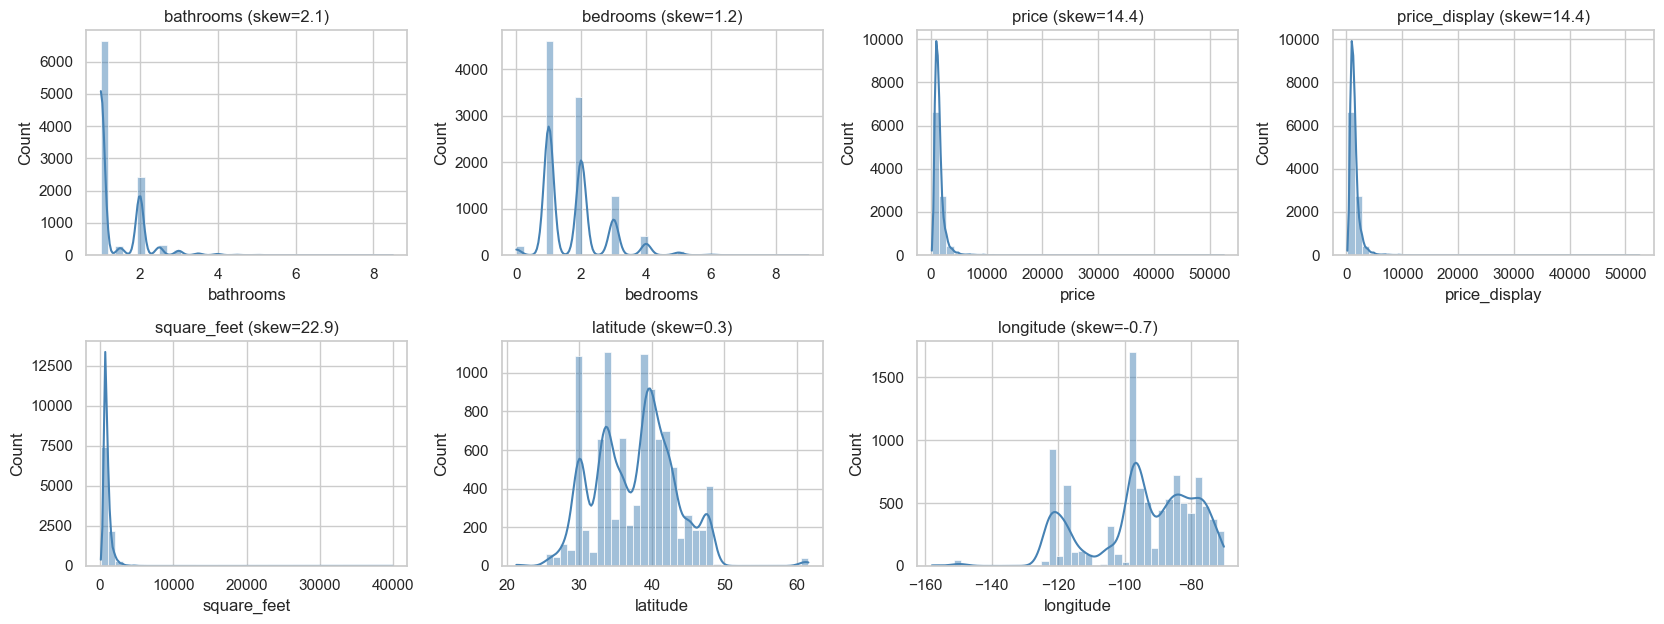

In [33]:
def grille(n_items, n_cols=4, h=3.2):
    n_rows = int(np.ceil(n_items / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, h * n_rows))
    return fig, np.array(axes).reshape(-1)

cols = num_cols[:MAX_PLOTS]
if cols:
    fig, axes = grille(len(cols))
    for ax, c in zip(axes, cols):
        s = df[c].dropna()
        sns.histplot(s, bins=40, kde=len(s) > 10, ax=ax, color="steelblue")
        ax.set_title(f"{c} (skew={s.skew():.1f})")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

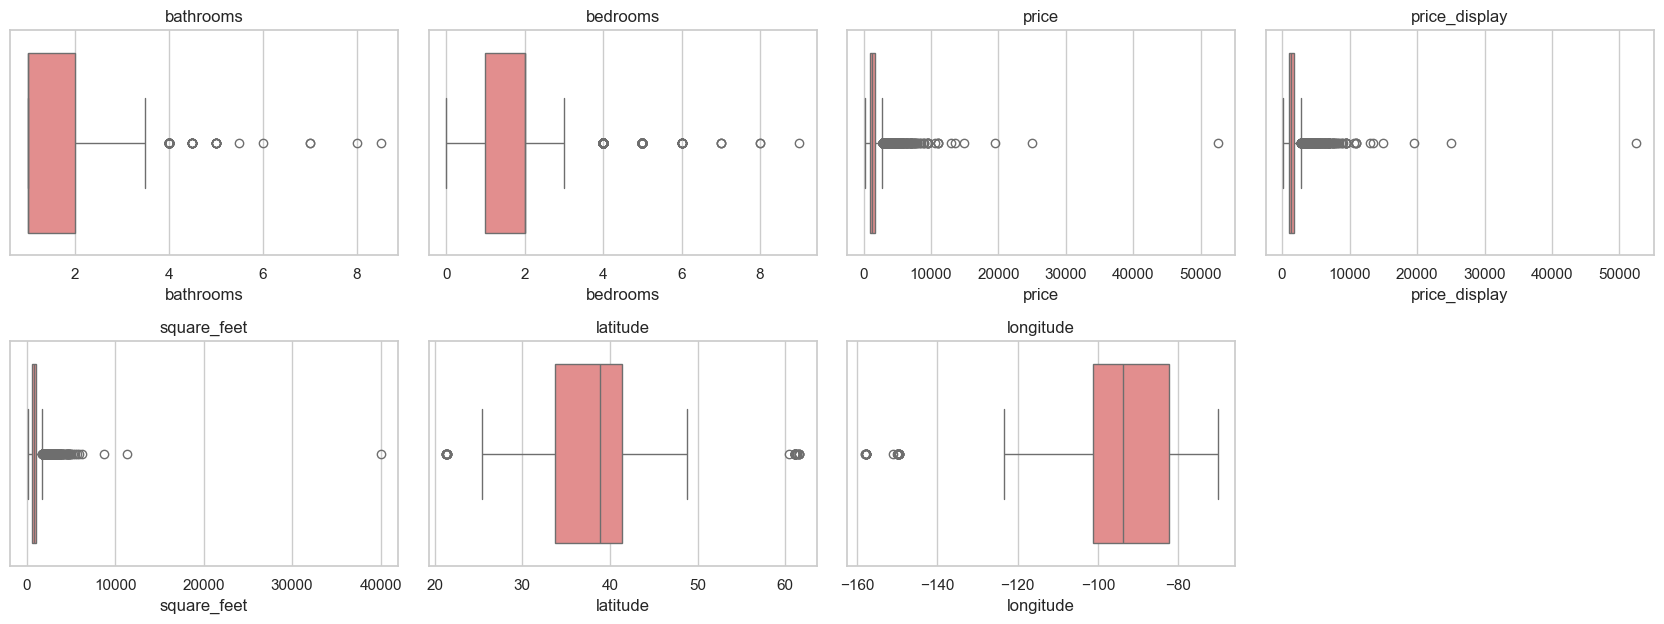

In [34]:
# Boxplots
if cols:
    fig, axes = grille(len(cols))
    for ax, c in zip(axes, cols):
        sns.boxplot(x=df[c], ax=ax, color="lightcoral")
        ax.set_title(c)
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

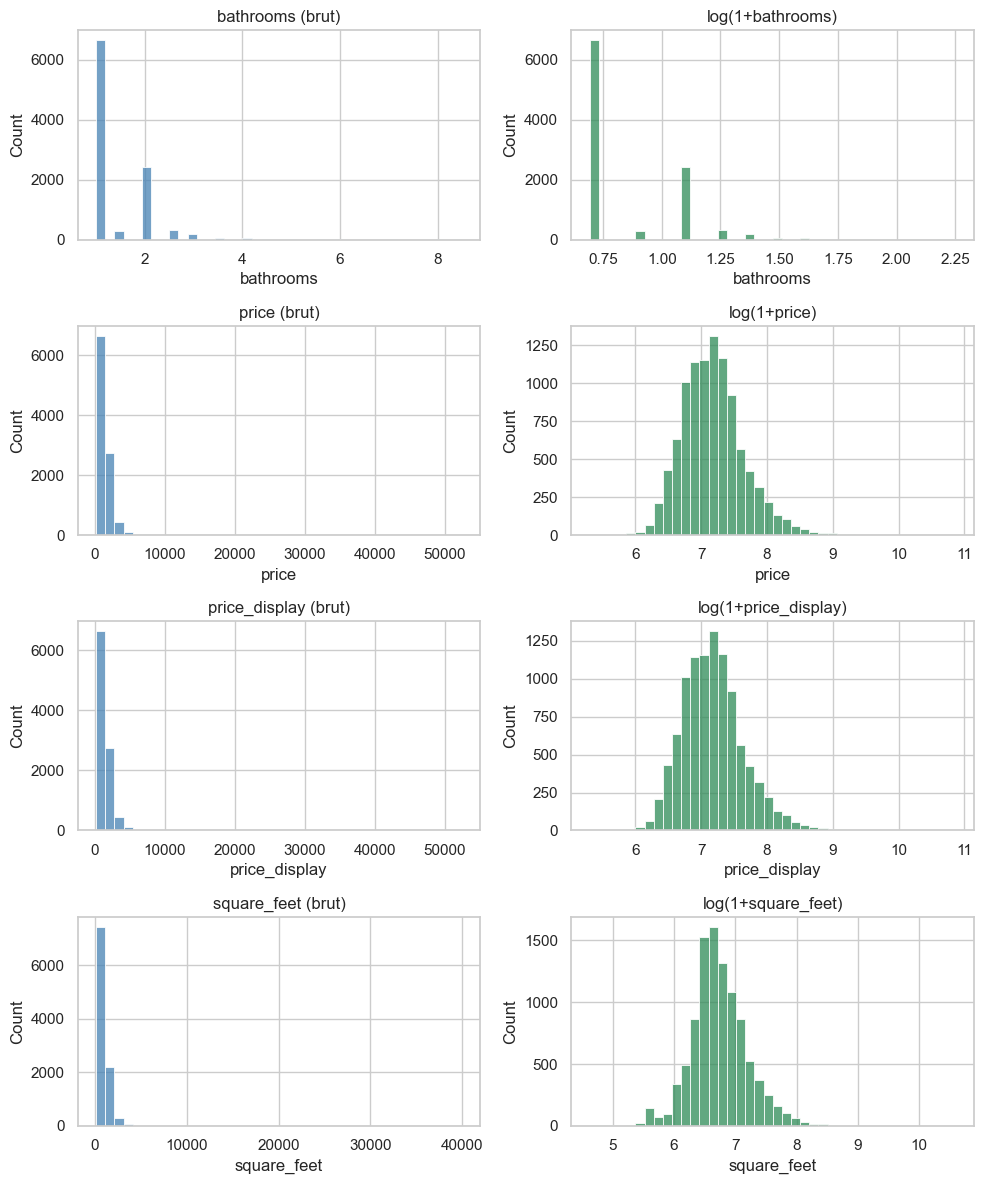

In [35]:
# Variables très asymétriques : comparaison avant / après log (si positives)
asym = [c for c in num_cols if abs(df[c].skew()) > 1 and (df[c].dropna() > 0).all()][:6]
if asym:
    fig, axes = plt.subplots(len(asym), 2, figsize=(10, 3 * len(asym)))
    axes = np.array(axes).reshape(len(asym), 2)
    for i, c in enumerate(asym):
        sns.histplot(df[c].dropna(), bins=40, ax=axes[i, 0], color="steelblue")
        axes[i, 0].set_title(f"{c} (brut)")
        sns.histplot(np.log1p(df[c].dropna()), bins=40, ax=axes[i, 1], color="seagreen")
        axes[i, 1].set_title(f"log(1+{c})")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune variable positive fortement asymétrique (|skew| > 1).")

## 8. Analyse univariée - variables catégorielles

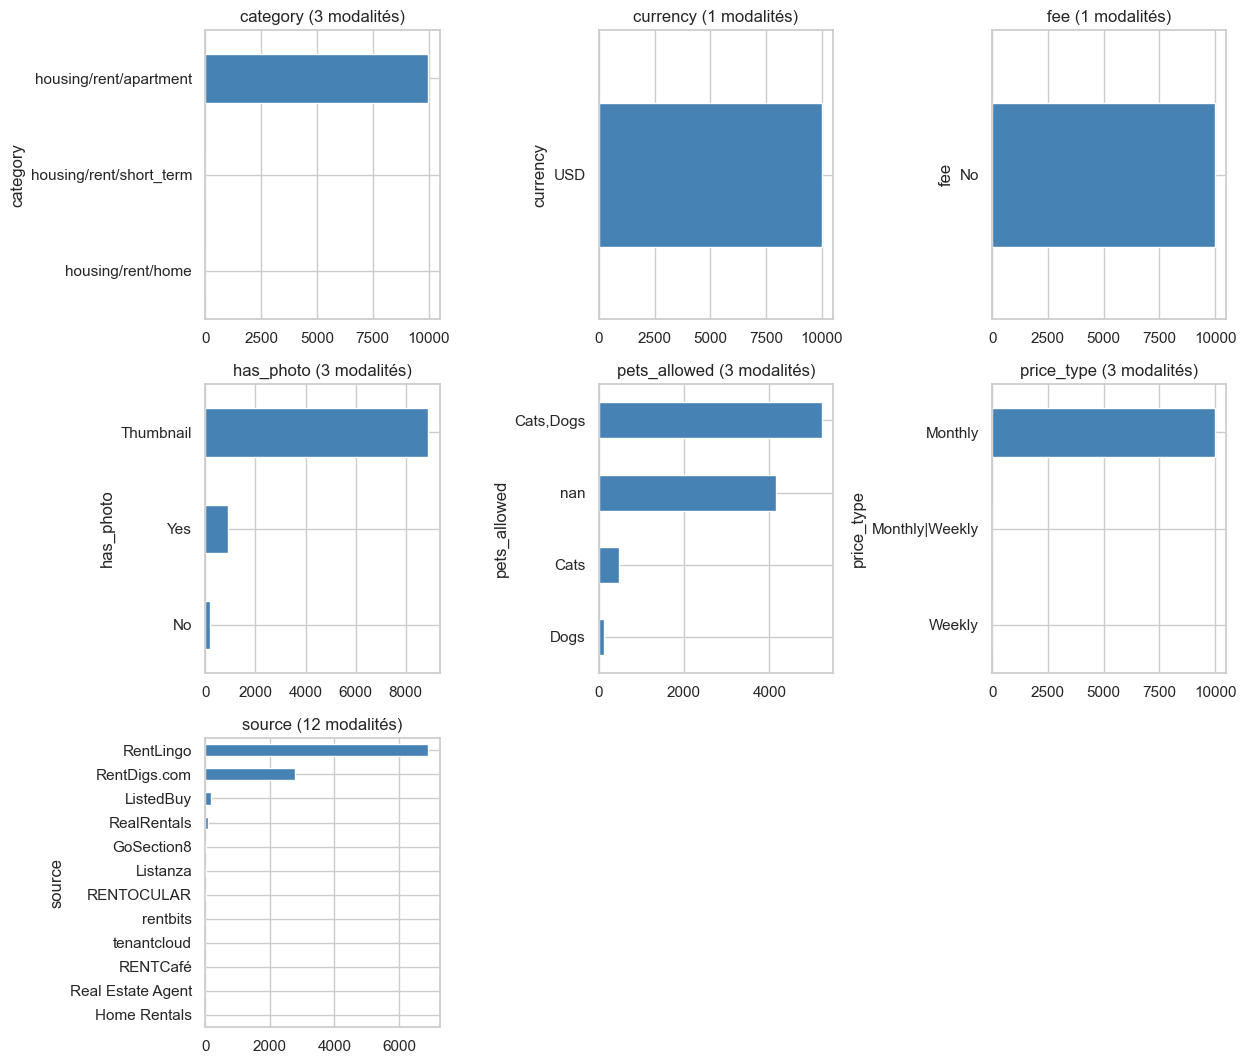

In [36]:
cols = cat_cols[:MAX_PLOTS]
if cols:
    fig, axes = grille(len(cols), n_cols=3, h=3.6)
    for ax, c in zip(axes, cols):
        vc = df[c].value_counts(dropna=False).head(15).sort_values()
        vc.index = vc.index.astype(str)
        vc.plot.barh(ax=ax, color="steelblue")
        ax.set_title(f"{c} ({df[c].nunique()} modalités)")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune variable catégorielle détectée.")

In [37]:
# Tableaux de fréquences
for c in cat_cols[:MAX_PLOTS]:
    t = pd.DataFrame({"effectif": df[c].value_counts(dropna=False),
                      "pourcentage": df[c].value_counts(dropna=False, normalize=True) * 100})
    print(f"--- {c} ---")
    display(t.head(10))

--- category ---


,effectif,pourcentage
category,,
housing/rent/apartment,9996,99.96
housing/rent/home,2,0.02
housing/rent/short_term,2,0.02


--- currency ---


,effectif,pourcentage
currency,,
USD,10000,100.00


--- fee ---


,effectif,pourcentage
fee,,
No,10000,100.00


... (4 outputs left out)

--- price_type ---


,effectif,pourcentage
price_type,,
Monthly,9998,99.98
Weekly,1,0.01
Monthly|Weekly,1,0.01


--- source ---


,effectif,pourcentage
source,,
RentLingo,6912,69.12
RentDigs.com,2764,27.64
ListedBuy,179,1.79
RealRentals,69,0.69
GoSection8,31,0.31
Listanza,23,0.23
RENTOCULAR,16,0.16
rentbits,2,0.02
Home Rentals,1,0.01


In [38]:
# Colonnes texte / forte cardinalité : longueur et exemples
for c in text_cols:
    s = df[c].dropna().astype(str)
    print(f"--- {c} : longueur moyenne {s.str.len().mean():.0f} caractères, {df[c].nunique():,} valeurs distinctes")
    print(s.head(3).str[:100].tolist())

--- title : longueur moyenne 32 caractères, 9,350 valeurs distinctes
['Studio apartment 2nd St NE, Uhland Terrace NE, Washington, DC 20002', 'Studio apartment 814 Schutte Road', 'Studio apartment N Scott St, 14th St N, Arlington, VA 22209']
--- amenities : longueur moyenne 48 caractères, 2,254 valeurs distinctes
['Dishwasher,Elevator,Patio/Deck,Pool,Storage', 'Refrigerator', 'Refrigerator']
--- address : longueur moyenne 19 caractères, 6,658 valeurs distinctes
['814 Schutte Rd', '1717 12th Avenue', '350 West 50th St']
--- cityname : longueur moyenne 9 caractères, 1,574 valeurs distinctes
['Washington', 'Evansville', 'Arlington']
--- state : longueur moyenne 2 caractères, 51 valeurs distinctes
['DC', 'IN', 'VA']


## 9. Valeurs aberrantes (outliers)
Méthode IQR (1,5 x IQR) et score Z (|z| > 3).

In [39]:
lignes = []
for c in num_cols:
    s = df[c].dropna()
    if len(s) < 5:
        continue
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < bas) | (s > haut)).sum())
    z = np.abs(stats.zscore(s)) if s.std() > 0 else np.zeros(len(s))
    lignes.append({"colonne": c, "borne_basse": bas, "borne_haute": haut,
                   "outliers_IQR": n_iqr, "pct_IQR": 100 * n_iqr / len(s),
                   "outliers_Z>3": int((z > 3).sum())})
outliers = pd.DataFrame(lignes).sort_values("pct_IQR", ascending=False) if lignes else pd.DataFrame()
display(outliers)

,colonne,borne_basse,borne_haute,outliers_IQR,pct_IQR,outliers_Z>3
4,square_feet,-27.50,"1,776.50",622,6.22,107
3,price_display,-170.00,"2,814.00",618,6.18,123
2,price,-170.00,"2,814.00",618,6.18,123
1,bedrooms,-0.50,3.50,514,5.14,110
0,bathrooms,-0.50,3.50,72,0.72,138
5,latitude,22.17,52.85,56,0.56,44
6,longitude,-129.94,-53.57,56,0.56,56


In [40]:
# Aperçu des lignes les plus extrêmes pour la colonne la plus touchée
if not outliers.empty and outliers.iloc[0]["outliers_IQR"] > 0:
    c = outliers.iloc[0]["colonne"]
    print(f"Valeurs extrêmes de '{c}' :")
    display(df.loc[df[c].sort_values(ascending=False).head(5).index])

Valeurs extrêmes de 'square_feet' :


,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
9998,5668662559,housing/rent/apartment,One BR in New York NY 10069,"Monthly Rent$4,605 -to $4,790AmenitiesThe Aldy...","Basketball,Cable or Satellite,Doorman,Hot Tub,...",NaN,1.00,USD,No,Thumbnail,NaN,4790,"4,790.00",Monthly,40000,NaN,New York,NY,40.77,-73.99,Listanza,2019-12-26 12:09:46
9997,5668643292,housing/rent/apartment,Six BR 9908 Bentcross Drive,"This unit is located at 9908 Bentcross Drive, ...",NaN,8.50,6.00,USD,No,Thumbnail,NaN,11000,"11,000.00",Monthly,11318,9908 Bentcross Dr,Potomac,MD,39.03,-77.24,RentLingo,2019-12-26 11:42:40
9996,5668640983,housing/rent/apartment,Six BR 256 Las Entradas,"This unit is located at 256 Las Entradas, Mont...",NaN,8.00,6.00,USD,No,Thumbnail,NaN,25000,"25,000.00",Monthly,8716,256 Las Entradas,Montecito,CA,34.43,-119.63,RentLingo,2019-12-26 11:40:19
9995,5630240092,housing/rent/apartment,Five BR 5407 Abbott Place - Abbott,This unit is located at 5407 Abbott Place - Ab...,NaN,4.00,5.00,USD,No,Thumbnail,NaN,6000,"6,000.00",Monthly,6300,5407 Abbott Place Abbott,Edina,MN,44.90,-93.32,RentLingo,2019-11-30 11:22:55
9994,5664597657,housing/rent/apartment,Six BR 2536 W Canyon Ridge Rd.,This unit is located at 2536 W Canyon Ridge Rd...,NaN,4.00,6.00,USD,No,Thumbnail,NaN,3000,"3,000.00",Monthly,5921,2536 W Canyon Ridge Road,Saint George,UT,37.08,-113.58,RentLingo,2019-12-22 12:18:23


## 10. Analyse bivariée - numérique vs numérique

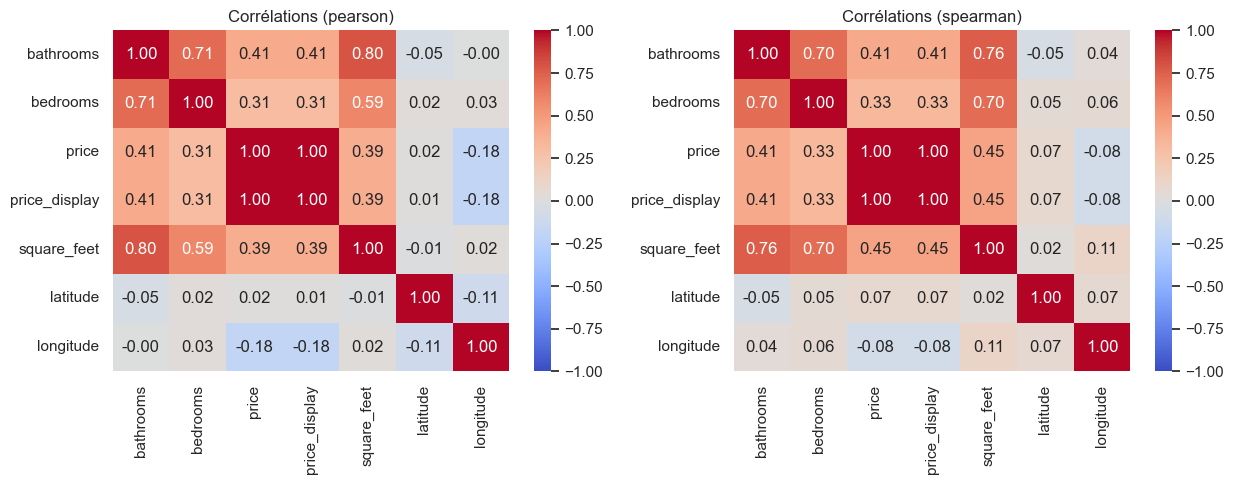

In [41]:
if len(num_cols) >= 2:
    cm = num_cols[:30]
    fig, axes = plt.subplots(1, 2, figsize=(max(12, 0.9 * len(cm) * 2), max(5, 0.7 * len(cm))))
    for ax, methode in zip(axes, ["pearson", "spearman"]):
        sns.heatmap(df[cm].corr(method=methode), annot=len(cm) <= 12, fmt=".2f",
                    cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
        ax.set_title(f"Corrélations ({methode})")
    plt.tight_layout()
    plt.show()
else:
    print("Moins de 2 variables numériques.")

In [42]:
# Paires fortement corrélées
if len(num_cols) >= 2:
    corr = df[num_cols].corr(method="spearman")
    paires = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
                  .stack().rename("spearman").reset_index())
    paires.columns = ["var_1", "var_2", "spearman"]
    fortes = paires[paires["spearman"].abs() >= CORR_THRESHOLD].sort_values("spearman", key=abs, ascending=False)
    display(fortes if not fortes.empty else f"Aucune paire avec |corrélation| >= {CORR_THRESHOLD}")

,var_1,var_2,spearman
11,price,price_display,1.00
3,bathrooms,square_feet,0.76
0,bathrooms,bedrooms,0.70
8,bedrooms,square_feet,0.70


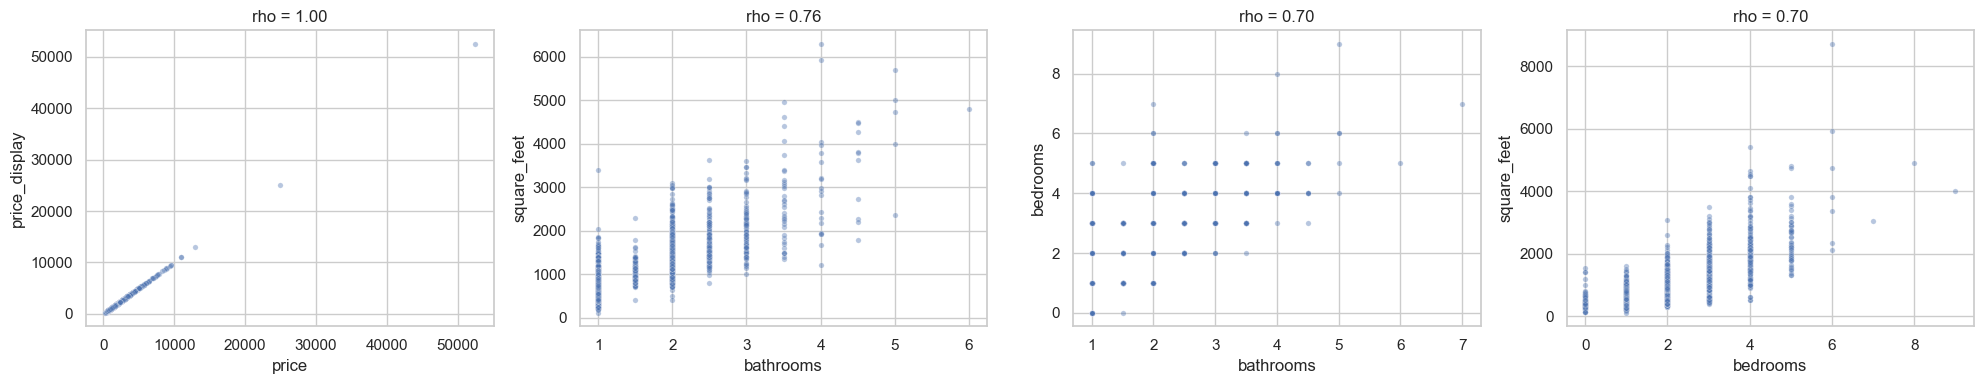

In [43]:
# Nuages de points des 4 paires les plus corrélées
if len(num_cols) >= 2 and not fortes.empty:
    top = fortes.head(4)
    fig, axes = plt.subplots(1, len(top), figsize=(5 * len(top), 4))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, top.iterrows()):
        d = df[[r["var_1"], r["var_2"]]].dropna()
        d = d.sample(min(len(d), SAMPLE_SIZE), random_state=0)
        sns.scatterplot(data=d, x=r["var_1"], y=r["var_2"], alpha=.4, s=15, ax=ax)
        ax.set_title(f"rho = {r['spearman']:.2f}")
    plt.tight_layout()
    plt.show()

In [44]:
# Matrice de nuages de points (si peu de variables)
if 2 <= len(num_cols) <= 6:
    d = df[num_cols].dropna()
    sns.pairplot(d.sample(min(len(d), 1000), random_state=0),
                 corner=True, plot_kws={"alpha": .4, "s": 12})
    plt.show()

## 11. Analyse bivariée - numérique vs catégorielle
Test de Kruskal-Wallis (non paramétrique) : une p-value faible indique que la variable numérique diffère selon les modalités.

In [45]:
cats_ok = [c for c in cat_cols if 2 <= df[c].nunique() <= 15]
lignes = []
for c in cats_ok:
    for v in num_cols:
        groupes = [g[v].dropna().values for _, g in df.groupby(c) if g[v].notna().sum() >= 3]
        if len(groupes) >= 2:
            try:
                h, p = stats.kruskal(*groupes)
                lignes.append({"catégorielle": c, "numérique": v, "H": h, "p_value": p})
            except ValueError:
                pass
kw = pd.DataFrame(lignes).sort_values("p_value") if lignes else pd.DataFrame()
display(kw.head(20) if not kw.empty else "Pas de combinaison testable")

,catégorielle,numérique,H,p_value
20,source,longitude,722.49,0.00
18,source,square_feet,235.67,0.00
16,source,price,218.08,0.00
17,source,price_display,217.56,0.00
7,pets_allowed,bathrooms,177.77,0.00
11,pets_allowed,square_feet,157.98,0.00
12,pets_allowed,latitude,134.97,0.00
8,pets_allowed,bedrooms,122.06,0.00
6,has_photo,longitude,114.10,0.00
14,source,bathrooms,99.55,0.00


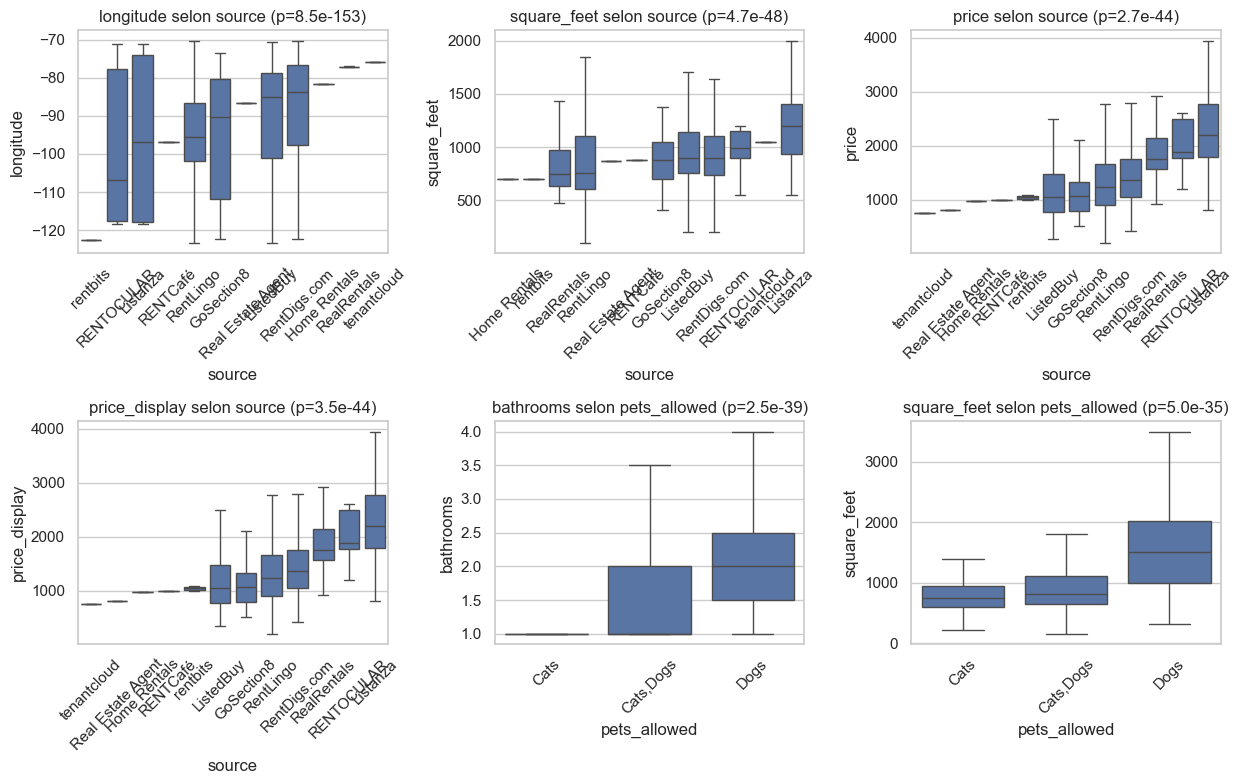

In [46]:
# Boxplots des combinaisons les plus significatives
if not kw.empty:
    top = kw.head(6)
    fig, axes = grille(len(top), n_cols=3, h=4)
    for ax, (_, r) in zip(axes, top.iterrows()):
        d = df[[r["catégorielle"], r["numérique"]]].dropna()
        ordre = d.groupby(r["catégorielle"])[r["numérique"]].median().sort_values().index
        sns.boxplot(data=d, x=r["catégorielle"], y=r["numérique"], order=ordre, ax=ax, showfliers=False)
        ax.set_title(f"{r['numérique']} selon {r['catégorielle']} (p={r['p_value']:.1e})")
        ax.tick_params(axis="x", rotation=45)
    for ax in axes[len(top):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 12. Analyse bivariée - catégorielle vs catégorielle
V de Cramér : 0 = aucune association, 1 = association parfaite.

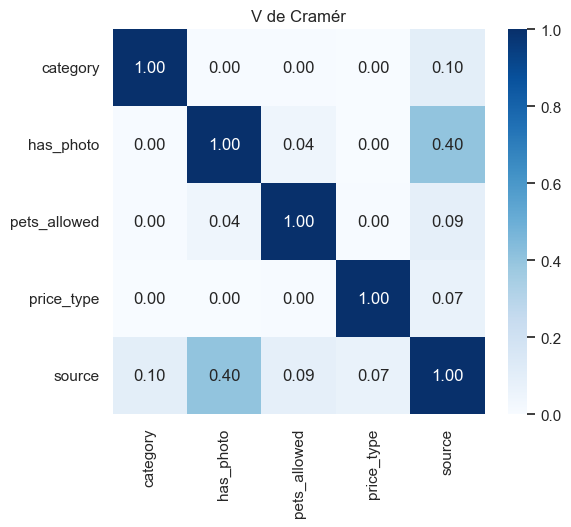

In [47]:
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    k = min(t.shape) - 1
    return np.sqrt(chi2 / (n * k)) if k > 0 and n > 0 else np.nan

cc = [c for c in cat_cols if 2 <= df[c].nunique() <= MAX_CAT_CARD][:15]
if len(cc) >= 2:
    mat = pd.DataFrame(index=cc, columns=cc, dtype=float)
    for a in cc:
        for b in cc:
            d = df[[a, b]].dropna()
            mat.loc[a, b] = 1.0 if a == b else cramers_v(d[a], d[b])
    plt.figure(figsize=(max(6, 0.7 * len(cc)), max(5, 0.6 * len(cc))))
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
    plt.title("V de Cramér")
    plt.show()
else:
    print("Moins de 2 variables catégorielles exploitables.")

## 13. Analyse de la variable cible (optionnel)
Renseignez `TARGET` dans la configuration pour activer cette partie.

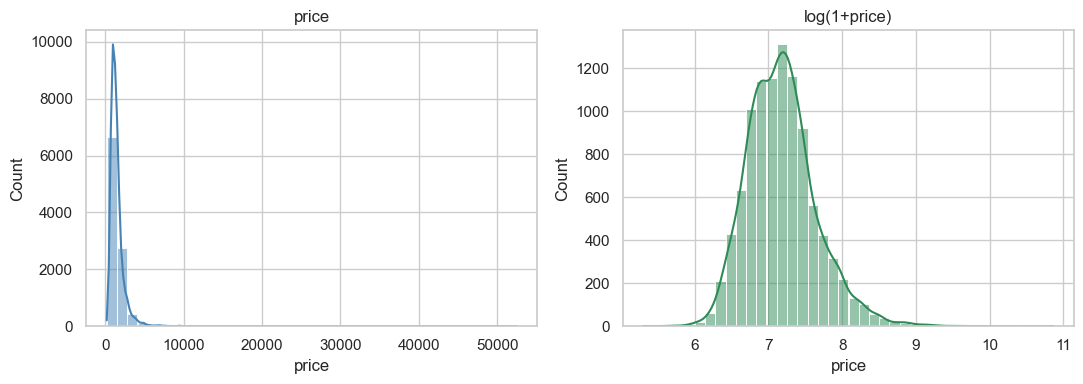

Corrélation de Spearman avec la cible :


,spearman
price_display,1.00
square_feet,0.45
bathrooms,0.41
bedrooms,0.33
longitude,-0.08
latitude,0.07


,catégorielle,numérique,H,p_value
16,source,price,218.08,0.00
9,pets_allowed,price,82.72,0.00
2,has_photo,price,42.60,0.00


In [48]:
if TARGET is None or TARGET not in df.columns:
    print("Aucune variable cible définie : partie ignorée (renseignez TARGET dans la configuration).")
elif pd.api.types.is_numeric_dtype(df[TARGET]) and df[TARGET].nunique() > 10:
    # cible numérique (régression)
    s = df[TARGET].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.histplot(s, bins=40, kde=True, ax=axes[0], color="steelblue")
    axes[0].set_title(f"{TARGET}")
    if (s > 0).all():
        sns.histplot(np.log1p(s), bins=40, kde=True, ax=axes[1], color="seagreen")
        axes[1].set_title(f"log(1+{TARGET})")
    plt.tight_layout()
    plt.show()
    autres = [c for c in num_cols if c != TARGET]
    if autres:
        cor = df[autres + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
        print("Corrélation de Spearman avec la cible :")
        display(cor.to_frame("spearman"))
    if not kw.empty:
        display(kw[kw["numérique"] == TARGET].head(10))
else:
    # cible catégorielle (classification)
    vc = df[TARGET].value_counts(normalize=True) * 100
    display(vc.to_frame("%"))
    vc.sort_values().plot.barh(color="steelblue", title=f"Répartition de {TARGET}")
    plt.show()
    for c in num_cols[:6]:
        plt.figure(figsize=(6, 3))
        sns.boxplot(data=df, x=TARGET, y=c, showfliers=False)
        plt.show()

## 14. Analyse temporelle (si colonnes de dates)

time : de 2019-09-17 18:12:56 à 2019-12-26 12:09:46 (99 jours)


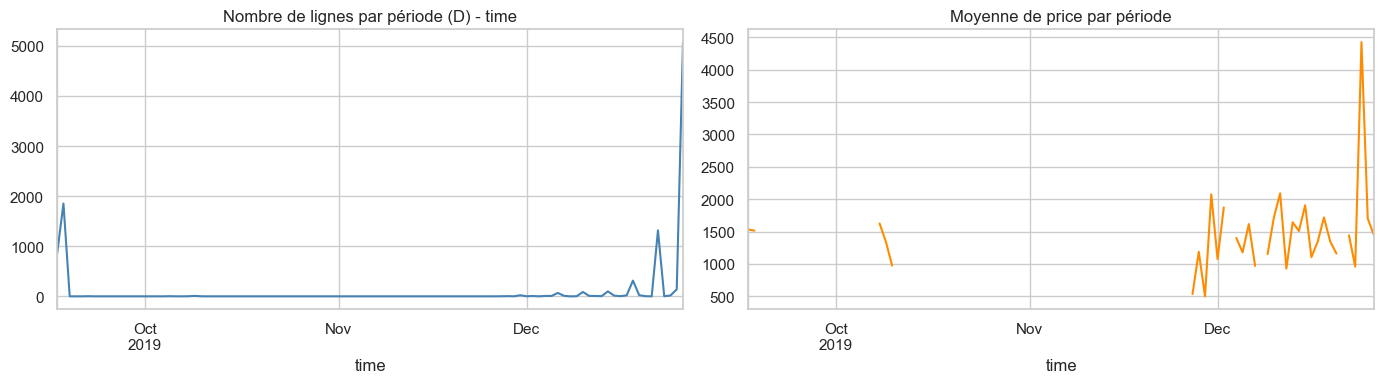

In [49]:
if not date_cols:
    print("Aucune colonne de date détectée (pensez à UNIX_TIME_COLS pour les timestamps Unix).")
for c in date_cols:
    s = df[c].dropna()
    if s.empty:
        continue
    print(f"{c} : de {s.min()} à {s.max()} ({(s.max() - s.min()).days} jours)")
    etendue = (s.max() - s.min()).days
    freq = "D" if etendue <= 120 else ("W" if etendue <= 730 else "M")
    serie = df.set_index(c).sort_index().resample(freq).size()
    fig, axes = plt.subplots(1, 2 if num_cols else 1, figsize=(14, 4))
    axes = np.atleast_1d(axes)
    serie.plot(ax=axes[0], color="steelblue")
    axes[0].set_title(f"Nombre de lignes par période ({freq}) - {c}")
    if num_cols:
        ref = TARGET if TARGET in num_cols else num_cols[0]
        df.set_index(c).sort_index()[ref].resample(freq).mean().plot(ax=axes[1], color="darkorange")
        axes[1].set_title(f"Moyenne de {ref} par période")
    plt.tight_layout()
    plt.show()

## 15. Analyse géographique (si latitude / longitude)

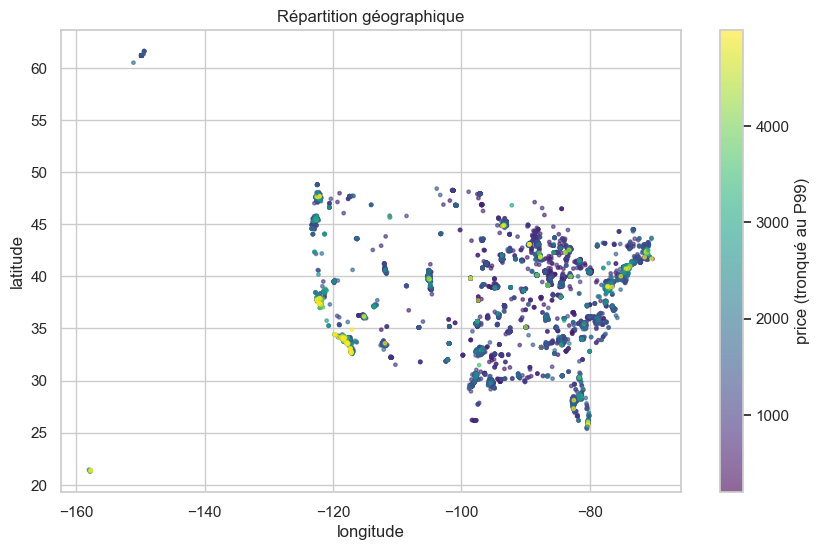

In [50]:
lat = next((c for c in df.columns if c.lower() in ("lat", "latitude")), None)
lon = next((c for c in df.columns if c.lower() in ("lon", "lng", "long", "longitude")), None)
if lat and lon:
    d = df[[lat, lon] + ([TARGET] if TARGET in num_cols else num_cols[:1])].dropna()
    d = d[(d[lat].between(-90, 90)) & (d[lon].between(-180, 180))]
    ref = TARGET if TARGET in num_cols else (num_cols[0] if num_cols else None)
    plt.figure(figsize=(10, 6))
    if ref:
        sc = plt.scatter(d[lon], d[lat], c=d[ref].clip(upper=d[ref].quantile(.99)), cmap="viridis", s=6, alpha=.6)
        plt.colorbar(sc, label=f"{ref} (tronqué au P99)")
    else:
        plt.scatter(d[lon], d[lat], s=6, alpha=.6)
    plt.xlabel("longitude")
    plt.ylabel("latitude")
    plt.title("Répartition géographique")
    plt.show()
else:
    print("Pas de colonnes latitude / longitude détectées.")

## 16. Synthèse automatique
Résumé des principaux constats à compléter avec vos propres interprétations.

In [51]:
constats = []
constats.append(f"Jeu de données : {df.shape[0]:,} lignes, {df.shape[1]} colonnes "
                f"({len(num_cols)} numériques, {len(cat_cols)} catégorielles, {len(date_cols)} dates, "
                f"{len(id_cols)} identifiants, {len(text_cols)} textes).")

fort_manq = manq[manq["pct_manquants"] > 30]
if len(fort_manq):
    constats.append(f"Colonnes avec plus de 30 % de manquants : {fort_manq.index.tolist()} -> imputer ou supprimer.")
else:
    constats.append("Pas de colonne avec plus de 30 % de valeurs manquantes.")

nd = int(df.duplicated().sum())
constats.append(f"{nd:,} lignes dupliquées" + (" -> à supprimer." if nd else "."))
if constantes:
    constats.append(f"Colonnes constantes à supprimer : {constantes}.")

skewed = [c for c in num_cols if abs(df[c].skew()) > 1]
if skewed:
    constats.append(f"Variables très asymétriques (|skew| > 1) : {skewed} -> envisager une transformation log.")

if not outliers.empty:
    lourds = outliers[outliers["pct_IQR"] > 5]["colonne"].tolist()
    if lourds:
        constats.append(f"Variables avec plus de 5 % d'outliers (IQR) : {lourds}.")

if len(num_cols) >= 2 and not fortes.empty:
    p = fortes.iloc[0]
    constats.append(f"Paire la plus corrélée : {p['var_1']} / {p['var_2']} (rho = {p['spearman']:.2f}).")

if not kw.empty and kw.iloc[0]["p_value"] < 0.05:
    r = kw.iloc[0]
    constats.append(f"Association numérique/catégorielle la plus nette : {r['numérique']} selon {r['catégorielle']} (p = {r['p_value']:.1e}).")

for c in constats:
    print("-", c)

- Jeu de données : 10,000 lignes, 22 colonnes (7 numériques, 7 catégorielles, 1 dates, 2 identifiants, 5 textes).
- Colonnes avec plus de 30 % de manquants : ['pets_allowed', 'amenities', 'address'] -> imputer ou supprimer.
- 0 lignes dupliquées.
- Colonnes constantes à supprimer : ['currency', 'fee'].
- Variables très asymétriques (|skew| > 1) : ['bathrooms', 'bedrooms', 'price', 'price_display', 'square_feet'] -> envisager une transformation log.
- Variables avec plus de 5 % d'outliers (IQR) : ['square_feet', 'price_display', 'price', 'bedrooms'].
- Paire la plus corrélée : price / price_display (rho = 1.00).
- Association numérique/catégorielle la plus nette : longitude selon source (p = 8.5e-153).


## 17. Export des données nettoyées

In [52]:
# Retire les colonnes constantes ; décommentez pour supprimer aussi les doublons
df_propre = df.drop(columns=constantes)
# df_propre = df_propre.drop_duplicates()
df_propre.to_csv("donnees_nettoyees.csv", index=False)
print(f"Fichier 'donnees_nettoyees.csv' enregistré ({df_propre.shape[0]:,} lignes, {df_propre.shape[1]} colonnes).")

Fichier 'donnees_nettoyees.csv' enregistré (10,000 lignes, 20 colonnes).
